# LA LA Stay · Airbnb Los Ángeles
### Análisis de datos — Andrés Arismendi (Uniandes)

**Fuente:** Inside Airbnb, `listings.csv.gz` de Los Ángeles (extracción del 14 al 16 de septiembre de 2026), guardado en `data/raw/`.

In [49]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', 100)

In [ ]:
# Rutas del proyecto: funciona desde cualquier carpeta dentro del repositorio
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'data').is_dir():
            return folder
    return start

ROOT = find_project_root()
RAW_FILE = ROOT / 'data' / 'raw' / 'listings.csv.gz'
print('Archivo:', RAW_FILE)

### Cargar los datos
`id` y `host_id` se leen como **texto**: los IDs de Inside Airbnb tienen hasta 19 dígitos y, si se leen como número o pasan por Excel, pierden los últimos dígitos.

In [52]:
df = pd.read_csv(RAW_FILE, compression='gzip', low_memory=False,
                 dtype={'id': str, 'host_id': str})

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
df.head()

Filas: 43,781 | Columnas: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,20260914002257,2026-09-15,NaN,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3008,https://www.airbnb.com/users/show/3008,1462506333679450606,https://www.airbnb.com/users/profile/146250633...,⁨Chas.⁩,NaN,17,11,15,7,"Los Angeles, CA",Professional and technical writer.\nLiterary C...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/d17cf...,NaN,2,NaN,NaN,t,t,NaN,Hollywood,City of Los Angeles,34.096250,-118.346050,Private room in rental unit,Private room,1,NaN,1 shared bath,1.0,1.0,"[""1801 Beekman Luxury Spa Goat Milk Soap & Han...",$76.31,2027-02-02,2027-03-04,2289.31,76.31,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,NaN,t,6,21,21,246,2026-09-15,47,1,0,21,2,60,4579.0,2014-06-09,2026-05-26,4.87,4.83,4.94,5.00,4.98,4.96,4.87,NaN,NaN,2,0,2,0,0.31
1,2732,https://www.airbnb.com/rooms/2732,20260914002257,2026-09-15,NaN,Zen Life at the Beach,An oasis of tranquility awaits you.,NaN,https://a0.muscache.com/pictures/1082993/c5a99...,3041,https://www.airbnb.com/users/show/3041,1462506335238008418,https://www.airbnb.com/users/profile/146250633...,Yogapriestess,NaN,17,11,15,8,"Santa Monica, CA",I have been teaching yoga and meditation for 3...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/3041/profile_...,NaN,2,NaN,NaN,t,t,NaN,Santa Monica,Other Cities,34.004400,-118.480950,Private room in rental unit,Private room,1,NaN,1 private bath,1.0,1.0,"[""Refrigerator"", ""Private patio or balcony"", ""...",$215.21,2026-09-15,2026-09-22,1506.50,215.21,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",7.0,27.0,7.0,7.0,27.0,27.0,7.0,27.0,NaN,t,30,60,90,365,2026-09-15,24,0,0,108,0,0,0.0,2011-06-06,2022-08-21,4.41,4.26,4.58,4.39,4.48,4.91,4.22,228269,NaN,2,1,1,0,0.13
2,6033,https://www.airbnb.com/rooms/6033,20260914002257,2026-09-14,NaN,Poolside Serenity Studio,Our distinctive bachelor's studio for 1-3 gues...,NaN,https://a0.muscache.com/pictures/458111/986c76...,11619,https://www.airbnb.com/users/show/11619,1462506670443088558,https://www.airbnb.com/users/profile/146250667...,Sarah,NaN,17,5,15,8,"California, United States",My name is Sarah working in property design an...,NaN,NaN,Na

## 1 · Pasar las columnas JSON a columnas
Dos columnas guardan texto en formato JSON: `price_quote_raw` (objeto) y `amenities` (lista). Primero lo confirmamos.

In [53]:
import json

def looks_like_json(series, sample=500):
    values = series.dropna().astype(str).head(sample)
    if values.empty or not values.str.strip().str[:1].isin(['{', '[']).all():
        return False
    try:
        values.map(json.loads)
        return True
    except (ValueError, TypeError):
        return False

json_columns = [col for col in df.select_dtypes('object') if looks_like_json(df[col])]
print('Columnas JSON:', json_columns)
print('Shape inicial:', df.shape)

Columnas JSON: ['amenities', 'price_quote_raw']
Shape inicial: (43781, 90)


C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2496341735.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  json_columns = [col for col in df.select_dtypes('object') if looks_like_json(df[col])]


### 1.1 · `price_quote_raw`: cada llave es una columna
Cada fila trae `{"quote": {...}}` con 17 llaves. Cada llave pasa a una columna con el prefijo `quote_`.

La llave `raw_price_line_items` es a su vez una **lista** de cobros (hasta 12 por anuncio), y cada cobro tiene 4 llaves: `amount`, `item_type`, `description` y `price_string`. Se expande por posición: `quote_line_item_1_amount`, `quote_line_item_1_item_type`, …, `quote_line_item_12_price_string`. Si un anuncio tiene menos cobros, las columnas sobrantes quedan vacías.

In [54]:
quotes = df['price_quote_raw'].map(lambda raw: json.loads(raw)['quote'] if pd.notna(raw) else {})
quote_df = pd.json_normalize(quotes.tolist()).add_prefix('quote_').set_index(df.index)

# Expandir la lista de cobros por posición
line_items = quote_df.pop('quote_raw_price_line_items')
item_keys = ['amount', 'item_type', 'description', 'price_string']
max_items = int(line_items.map(lambda x: len(x) if isinstance(x, list) else 0).max())

items_df = pd.DataFrame(
    [[(items[i].get(key) if isinstance(items, list) and i < len(items) else None)
      for i in range(max_items) for key in item_keys]
     for items in line_items],
    columns=[f'quote_line_item_{i + 1}_{key}' for i in range(max_items) for key in item_keys],
    index=df.index,
)

print('Llaves de quote:', quote_df.shape[1] + 1, '(incluye raw_price_line_items)')
print('Máximo de cobros por anuncio:', max_items, '->', items_df.shape[1], 'columnas de cobros')

Llaves de quote: 17 (incluye raw_price_line_items)
Máximo de cobros por anuncio: 12 -> 48 columnas de cobros


In [55]:
# Tipos de dato: montos a número, fechas a fecha, banderas a booleano
money = ['quote_taxes', 'quote_total_price', 'quote_discount_amount', 'quote_price_per_night',
         'quote_nightly_subtotal', 'quote_discounted_subtotal']
quote_df[money] = quote_df[money].apply(pd.to_numeric, errors='coerce')
date_cols = [c for c in quote_df.columns if c.endswith('_date')]
quote_df[date_cols] = quote_df[date_cols].apply(pd.to_datetime)
for col in ['quote_is_available', 'quote_is_monthly_priced']:
    quote_df[col] = quote_df[col].astype('boolean')

amount_cols = [c for c in items_df.columns if c.endswith('_amount')]
items_df[amount_cols] = items_df[amount_cols].apply(pd.to_numeric, errors='coerce')

df = pd.concat([df.drop(columns=['price_quote_raw']), quote_df, items_df], axis=1)
print('Shape después de price_quote_raw:', df.shape)

Shape después de price_quote_raw: (43781, 153)


In [56]:
# Llaves que vienen vacías en TODAS las filas (se conservan, pero conviene saberlo)
empty_quote = [c for c in quote_df.columns if quote_df[c].isna().all()]
print('Llaves de quote siempre vacías:', empty_quote)

Llaves de quote siempre vacías: ['quote_date_match', 'quote_service_fee', 'quote_cleaning_fee', 'quote_returned_checkin_date', 'quote_returned_checkout_date']


### 1.2 · `amenities`
`amenities` es una **lista de textos, sin llaves** (por ejemplo `["Wifi", "Kitchen", "Pool"]`). Pasarla a columnas significa crear **una columna por servicio** (1 si el anuncio lo tiene, 0 si no). Aquí solo se calcula cuántas columnas resultarían, sin crearlas todavía.

In [57]:
amenities_list = df['amenities'].map(lambda raw: [a.strip().lower() for a in json.loads(raw)] if pd.notna(raw) else [])
n_amenities = amenities_list.explode().nunique()
print(f'Servicios distintos: {n_amenities:,}')
print(f'Shape si cada servicio fuera una columna: ({df.shape[0]:,}, {df.shape[1] - 1 + n_amenities:,})')

Servicios distintos: 9,820
Shape si cada servicio fuera una columna: (43,781, 9,972)


### 1.3 · ¿Qué valores toma `amenities`?
Tabla de frecuencia de **todos** los servicios: en cuántos anuncios aparece cada uno y qué porcentaje del total representa.

In [58]:
amenity_freq = (amenities_list.explode().dropna()
                .value_counts()
                .rename_axis('amenity')
                .reset_index(name='anuncios'))
amenity_freq['% anuncios'] = (amenity_freq['anuncios'] / len(df) * 100).round(2)

print(f'Servicios distintos: {len(amenity_freq):,}')
print(f'Anuncios sin ningún servicio: {(amenities_list.str.len() == 0).sum()}')
amenity_freq.head(60)

Servicios distintos: 9,820
Anuncios sin ningún servicio: 47


,amenity,anuncios,% anuncios
0,smoke alarm,41723,95.30
1,wifi,40962,93.56
2,carbon monoxide alarm,38438,87.80
3,kitchen,38417,87.75
4,hot water,35177,80.35
5,hangers,33104,75.61
6,hair dryer,31992,73.07
7,essentials,30777,70.30
8,dishes and silverware,30707,70.14
9,microwave,30578,69.84


**Distribución por frecuencia:** cuántos servicios hay en cada rango de popularidad.

In [59]:
n = len(df)
bands = pd.cut(amenity_freq['anuncios'],
               bins=[0, 1, 0.001 * n, 0.01 * n, 0.05 * n, 0.90 * n, n],
               labels=['1 solo anuncio', '2 anuncios a 0,1 %', '0,1 % – 1 %',
                       '1 % – 5 %', '5 % – 90 %', 'más de 90 %'])
band_table = bands.value_counts().sort_index().to_frame('servicios')
band_table['% de servicios'] = (band_table['servicios'] / len(amenity_freq) * 100).round(1)
band_table

,servicios,% de servicios
anuncios,,
1 solo anuncio,6633,67.5
"2 anuncios a 0,1 %",2751,28.0
"0,1 % – 1 %",238,2.4
1 % – 5 %,92,0.9
5 % – 90 %,104,1.1
más de 90 %,2,0.0


**Variantes del mismo servicio:** muchos servicios son el mismo con distinta marca, tamaño o detalle. Ejemplos por palabra clave:

In [60]:
for keyword in ['tv', 'wifi', 'shampoo', 'pool', 'parking', 'coffee']:
    variants = amenity_freq[amenity_freq['amenity'].str.contains(keyword, regex=False)]
    print(f"'{keyword}': {len(variants):,} variantes -> {variants['amenity'].head(6).tolist()}")

print('\nEjemplos de servicios que aparecen en un solo anuncio:')
print(amenity_freq.loc[amenity_freq['anuncios'] == 1, 'amenity'].sample(8, random_state=1).tolist())

'tv': 3,150 variantes -> ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv', '65 inch hdtv', 'hdtv with roku']
'wifi': 742 variantes -> ['wifi', 'pocket wifi', 'fast wifi – 364 mbps', 'fast wifi – 229 mbps', 'fast wifi – 87 mbps', 'fast wifi – 224 mbps']
'shampoo': 786 variantes -> ['shampoo', 'pantene shampoo', 'dove shampoo', 'public goods shampoo', 'native shampoo', 'generic shampoo']
'pool': 393 variantes -> ['pool', 'pool table', 'pool view', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
'parking': 73 variantes -> ['free parking on premises', 'free street parking', 'paid parking on premises', 'paid parking off premises', 'free driveway parking on premises – 1 space', 'free parking garage on premises']
'coffee': 62 variantes -> ['coffee maker', 'coffee', 'coffee maker: keurig coffee machine', 'coffee maker: drip coffee maker', 'coffee maker: nespresso', 'coffee maker: drip coffee maker, keurig coffee machine']

Ejemplos de serv

### 1.4 · Unificar las variantes de `amenities`
Cada servicio unificado se define con una **expresión regular** sobre el texto en minúsculas. Un anuncio tiene el servicio si **alguno** de sus textos coincide. Ejemplos:
- `tv` agrupa "tv", "hdtv", "55 inch hdtv with netflix"…
- `pool` agrupa "pool", "private pool", "shared outdoor pool…", pero **no** "pool table" ni "pool view".
- `washer` excluye "dishwasher"; `dryer` excluye "hair dryer".

In [61]:
import re

AMENITY_RULES = {
    # Básicos
    'wifi':              r'\bwi-?fi\b',
    'kitchen':           r'\bkitchen\b',
    'tv':                r'\b(?:hd)?tv\b',
    'workspace':         r'workspace',
    'coffee_maker':      r'coffee maker|espresso|nespresso|keurig',
    # Clima
    'air_conditioning':  r'air conditioning|\bac\b|a/c',
    'heating':           r'heating|\bheater\b',
    'fireplace':         r'fireplace',
    'ceiling_fan':       r'ceiling fan',
    # Lavado y baño
    'washer':            r'(?<!dish)washer',
    'dryer':             r'(?<!hair )\bdryer\b',
    'dishwasher':        r'dishwasher',
    'bathtub':           r'bathtub|soaking tub',
    # Exterior
    'pool':              r'\bpool\b(?! table)(?! view)',
    'hot_tub':           r'hot tub|jacuzzi',
    'patio_balcony':     r'patio|balcony',
    'backyard':          r'backyard',
    'bbq_grill':         r'\bbbq\b|barbecue|\bgrill\b',
    'outdoor_dining':    r'outdoor dining|outdoor furniture',
    'fire_pit':          r'fire pit',
    'garden':            r'\bgarden\b',
    # Acceso y estacionamiento
    'free_parking':      r'free .*parking',
    'paid_parking':      r'paid .*parking',
    'ev_charger':        r'ev charger',
    'private_entrance':  r'private entrance',
    'self_check_in':     r'self check-?in|keypad|lockbox|smart lock',
    'elevator':          r'\belevator\b',
    # Ocio
    'gym':               r'\bgym\b|exercise equipment',
    'sound_system':      r'sound system|bluetooth speaker',
    'game_console':      r'game console|playstation|\bps[45]\b|xbox|nintendo',
    # Ubicación / vistas
    'beach_access':      r'beach access|beachfront',
    'ocean_view':        r'ocean view|sea view|beach view',
    'mountain_view':     r'mountain view',
    'city_view':         r'city skyline view|city view',
    # Familias y políticas
    'crib':              r'\bcrib\b|pack .n play',
    'pets_allowed':      r'pets allowed',
    'long_term_stays':   r'long term stays allowed',
}

joined = amenities_list.map(' | '.join)          # todos los servicios del anuncio en un texto
for name, pattern in AMENITY_RULES.items():
    df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
df['amenities_count'] = amenities_list.str.len()

am_cols = [f'am_{name}' for name in AMENITY_RULES]
print(f'{len(am_cols)} servicios unificados creados | Shape: {df.shape}')

C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame

37 servicios unificados creados | Shape: (43781, 191)


C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
C:\Users\danie\AppData\Local\Temp\ipykernel_9444\2266905528.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame

In [62]:
# Verificación: qué textos originales quedaron dentro de algunos servicios unificados
exploded = amenity_freq.copy()
for name in ['tv', 'pool', 'washer', 'dryer', 'free_parking']:
    hits = exploded[exploded['amenity'].str.contains(AMENITY_RULES[name], regex=True)]
    print(f"{name}: {len(hits):,} variantes, p. ej. {hits['amenity'].head(4).tolist()}")

tv: 3,148 variantes, p. ej. ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv']
pool: 328 variantes, p. ej. ['pool', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
washer: 10 variantes, p. ej. ['washer', 'free washer – in unit', 'paid washer – in building', 'free washer – in building']
dryer: 10 variantes, p. ej. ['dryer', 'free dryer – in unit', 'free dryer – in building', 'paid dryer – in building']
free_parking: 37 variantes, p. ej. ['free parking on premises', 'free street parking', 'free driveway parking on premises – 1 space', 'free parking garage on premises']


### 1.5 · Frecuencia y relación con el precio
Para comparar precios usamos el **mercado objetivo del Charter**: hosts con 1–2 anuncios, con precio y **sin precio mensual** (`quote_is_monthly_priced = False`).
Se compara el **precio mediano** de los anuncios con y sin cada servicio. Es una comparación **descriptiva, no causal**: un servicio puede ir junto con propiedades más grandes o mejor ubicadas.

In [63]:
df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[\$,]', '', regex=True), errors='coerce')
target = df[df['calculated_host_listings_count'].between(1, 2)
            & df['price_num'].notna()
            & (df['quote_is_monthly_priced'] == False)]
print(f'Anuncios del mercado objetivo: {len(target):,}')

rows = []
for col in am_cols:
    has = target[col] == 1
    rows.append({
        'servicio': col.removeprefix('am_'),
        '% anuncios (todos)': df[col].mean() * 100,
        '% mercado objetivo': has.mean() * 100,
        'mediana con': target.loc[has, 'price_num'].median(),
        'mediana sin': target.loc[~has, 'price_num'].median(),
    })
amenity_summary = pd.DataFrame(rows)
amenity_summary['diferencia %'] = (amenity_summary['mediana con'] / amenity_summary['mediana sin'] - 1) * 100
amenity_summary['entre 5 % y 90 %'] = amenity_summary['% mercado objetivo'].between(5, 90)
amenity_summary = amenity_summary.sort_values('% mercado objetivo', ascending=False).round(1).reset_index(drop=True)
amenity_summary

C:\Users\danie\AppData\Local\Temp\ipykernel_9444\458186806.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[\$,]', '', regex=True), errors='coerce')


Anuncios del mercado objetivo: 8,782


,servicio,% anuncios (todos),% mercado objetivo,mediana con,mediana sin,diferencia %,entre 5 % y 90 %
0,wifi,98.6,98.9,283.5,221.5,28.0,False
1,tv,89.5,92.2,293.5,160.0,83.4,False
2,free_parking,83.4,91.6,287.5,238.5,20.5,False
3,air_conditioning,89.1,89.6,285.0,258.0,10.5,True
4,heating,84.6,87.5,289.2,220.5,31.2,True
5,kitchen,87.9,85.1,309.8,174.0,78.0,True
6,coffee_maker,68.1,78.3,298.6,209.0,42.9,True
7,washer,79.5,72.6,326.0,205.8,58.4,True
8,self_check_in,57.6,66.7,295.0,250.0,18.0,True
9,dryer,69.2,65.4,332.0,211.3,57.1,True


### 1.6 · Servicios seleccionados
Se descartan 9 servicios unificados:
- **Casi universales (más del 90 % del mercado objetivo):** `wifi`, `tv`, `free_parking`. No diferencian un anuncio de otro.
- **Muy raros (menos del 5 %):** `ocean_view`, `game_console`.
- **Diferencia de precio pequeña o ambigua:** `ceiling_fan`, `elevator`, `private_entrance` (5 %–8 %) y `paid_parking` (negativa: suele indicar zonas densas, no un servicio que agregue valor).

Se conservan los demás servicios más `amenities_count`, y se elimina la columna JSON original `amenities`.

In [64]:
DROP_AMENITIES = ['wifi', 'tv', 'free_parking', 'ocean_view', 'game_console',
                  'ceiling_fan', 'elevator', 'private_entrance', 'paid_parking']

df = df.drop(columns=[f'am_{name}' for name in DROP_AMENITIES] + ['amenities'])
am_cols = [col for col in df.columns if col.startswith('am_')]

print(f'Servicios conservados ({len(am_cols)}):')
print([col.removeprefix('am_') for col in am_cols])
print(f'\nShape: {df.shape}')

Servicios conservados (28):
['kitchen', 'workspace', 'coffee_maker', 'air_conditioning', 'heating', 'fireplace', 'washer', 'dryer', 'dishwasher', 'bathtub', 'pool', 'hot_tub', 'patio_balcony', 'backyard', 'bbq_grill', 'outdoor_dining', 'fire_pit', 'garden', 'ev_charger', 'self_check_in', 'gym', 'sound_system', 'beach_access', 'mountain_view', 'city_view', 'crib', 'pets_allowed', 'long_term_stays']

Shape: (43781, 182)


## 2 · Selección de columnas
### 2.1 · Variables derivadas antes de eliminar
Antes de quitar las columnas de la cotización se calculan dos variables útiles:
- `quote_nights`: noches que se cotizaron (de 1 a 365, según las noches mínimas).
- `base_nightly_rate`: **tarifa publicada por noche sin descuentos** = `quote_nightly_subtotal / quote_nights`. Existe solo para los anuncios con precio diario (no mensuales). Es una posible variable objetivo alternativa a `price`, que ya trae descuentos aplicados.

In [65]:
df['quote_nights'] = (df['quote_requested_checkout_date'] - df['quote_requested_checkin_date']).dt.days
# Solo tiene sentido con precio diario: en las cotizaciones mensuales no hay tarifa por noche
df['base_nightly_rate'] = (df['quote_nightly_subtotal'] / df['quote_nights']).where(df['quote_is_monthly_priced'] == False)

print(f"Anuncios con tarifa base: {df['base_nightly_rate'].notna().sum():,}")
print(pd.crosstab(df['base_nightly_rate'].notna(), df['quote_is_monthly_priced'],
                  rownames=['tiene tarifa base'], colnames=['precio mensual']))

Anuncios con tarifa base: 19,986
precio mensual     False  True 
tiene tarifa base              
False                753  18004
True               19986      0


C:\Users\danie\AppData\Local\Temp\ipykernel_9444\3713701452.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['quote_nights'] = (df['quote_requested_checkout_date'] - df['quote_requested_checkin_date']).dt.days
C:\Users\danie\AppData\Local\Temp\ipykernel_9444\3713701452.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['base_nightly_rate'] = (df['quote_nightly_subtotal'] / df['quote_nights']).where(df['quote_is_monthly_priced'] == False)


### 2.2 · Columnas a eliminar, por grupo
Cada grupo indica **por qué** se elimina. Al final se verifica que ninguna columna quede sin clasificar.

In [66]:
always_empty = [col for col in df.columns if df[col].isna().all()]

DROP_GROUPS = {
    'Vacías en todas las filas': always_empty,
    'Metadatos de la extracción': [
        'scrape_id', 'last_scraped', 'calendar_last_scraped', 'source', 'quote_currency',
        'quote_requested_checkin_date', 'quote_requested_checkout_date'],
    'URLs, identificadores secundarios y texto libre': [
        'listing_url', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url',
        'host_picture_url', 'host_name', 'name', 'description', 'host_about', 'host_location', 'license'],
    'Derivadas del precio (fuga hacia la variable objetivo)': [
        'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price',
        'price_quote_price_per_night', 'estimated_revenue_l365d', 'quote_total_price',
        'quote_price_per_night', 'quote_taxes', 'quote_discount_amount', 'quote_nightly_subtotal',
        'quote_discounted_subtotal'] + [c for c in df.columns if c.startswith('quote_line_item_')],
    'Redundantes': [
        'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights',
        'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
        'host_listings_count', 'calculated_host_listings_count_entire_homes',
        'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms',
        'hosts_time_as_user_years', 'hosts_time_as_user_months'],
    'Desempeño del anuncio (un anfitrión nuevo no lo conoce)': [
        'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
        'review_scores_checkin', 'review_scores_communication', 'review_scores_location',
        'review_scores_value', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'reviews_per_month',
        'first_review', 'availability_30', 'availability_60', 'availability_90', 'availability_eoy',
        'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
        'hosts_time_as_host_years', 'hosts_time_as_host_months', 'quote_is_available'],
}

# Una columna puede estar en "vacías" y en otro grupo; se cuenta una sola vez
to_drop = list(dict.fromkeys(col for cols in DROP_GROUPS.values() for col in cols))
missing = [col for col in to_drop if col not in df.columns]
assert not missing, f'Columnas inexistentes: {missing}'

summary = pd.DataFrame({'grupo': list(DROP_GROUPS),
                        'columnas': [len(cols) for cols in DROP_GROUPS.values()]})
display(summary)
print(f'Total a eliminar (sin repetir): {len(to_drop)}')

,grupo,columnas
0,Vacías en todas las filas,18
1,Metadatos de la extracción,7
2,"URLs, identificadores secundarios y texto libre",13
3,Derivadas del precio (fuga hacia la variable o...,60
4,Redundantes,12
5,Desempeño del anuncio (un anfitrión nuevo no l...,21


Total a eliminar (sin repetir): 131


In [67]:
df = df.drop(columns=to_drop)
print(f'Shape: {df.shape}')

Shape: (43781, 53)


### 2.3 · Columnas conservadas

In [68]:
KEEP_GROUPS = {
    'Clave': ['id'],
    'Variables objetivo (candidatas)': ['price_num', 'base_nightly_rate'],
    'Características de la propiedad': [
        'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude',
        'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'bathrooms_text'],
    'Servicios': [c for c in df.columns if c.startswith('am_')] + ['amenities_count'],
    'Filtros del mercado objetivo': [
        'calculated_host_listings_count', 'minimum_nights', 'maximum_nights',
        'quote_is_monthly_priced', 'quote_nights'],
    'Actividad (solo análisis, no van al modelo)': [
        'number_of_reviews', 'number_of_reviews_ltm', 'last_review', 'availability_365',
        'estimated_occupancy_l365d', 'has_availability'],
}
classified = [col for cols in KEEP_GROUPS.values() for col in cols]
unclassified = sorted(set(df.columns) - set(classified))
assert not unclassified, f'Columnas sin clasificar: {unclassified}'

df = df[classified]
df['last_review'] = pd.to_datetime(df['last_review'])
df['has_availability'] = df['has_availability'].map({'t': True, 'f': False}).astype('boolean')

display(pd.DataFrame({'grupo': list(KEEP_GROUPS), 'columnas': [len(c) for c in KEEP_GROUPS.values()]}))
print(f'Shape final: {df.shape}')

,grupo,columnas
0,Clave,1
1,Variables objetivo (candidatas),2
2,Características de la propiedad,10
3,Servicios,29
4,Filtros del mercado objetivo,5
5,"Actividad (solo análisis, no van al modelo)",6


Shape final: (43781, 53)


## 3 · Limpieza
Igual que el equipo del TEC, **no se borran filas**: los casos problemáticos se **marcan** con columnas 0/1 y se excluyen solo al entrenar.

Los pasos 3.2 y 3.4 reutilizan la lógica del notebook de limpieza del TEC (`Data_LA_Clean.ipynb`, Lorena Martínez). Para que los resultados sean comparables con los suyos, las medianas y los conteos de esos pasos se calculan sobre la misma población: **hosts con 1–2 anuncios**.

### 3.1 · Marcas del mercado objetivo
| Marca | Definición |
|---|---|
| `is_small_host` | El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter). |
| `has_price` | El anuncio tiene precio. |
| `is_monthly` | La cotización tiene precio mensual (`quote_is_monthly_priced`). |
| `in_target_market` | `is_small_host` **y** `has_price` **y no** `is_monthly`. |
| `is_hotel` | `room_type` es *Hotel room*: no corresponde a un anfitrión independiente. |
| `is_inactive` | Sin reseñas en los últimos 12 meses **y** ocupación estimada de 0 días. |
| `price_outlier` | Precio menor a USD 20 o mayor al percentil 99 **del mercado objetivo**. |

In [69]:
df['is_small_host'] = df['calculated_host_listings_count'].between(1, 2).astype(int)
df['has_price'] = df['price_num'].notna().astype(int)
df['is_monthly'] = df['quote_is_monthly_priced'].fillna(False).astype(int)
df['in_target_market'] = ((df['is_small_host'] == 1) & (df['has_price'] == 1)
                          & (df['is_monthly'] == 0)).astype(int)
df['is_hotel'] = (df['room_type'] == 'Hotel room').astype(int)
df['is_inactive'] = ((df['number_of_reviews_ltm'] == 0)
                     & (df['estimated_occupancy_l365d'] == 0)).astype(int)

PRICE_MIN = 20
PRICE_MAX = df.loc[df['in_target_market'] == 1, 'price_num'].quantile(0.99)
df['price_outlier'] = (df['has_price'].astype(bool)
                       & ((df['price_num'] < PRICE_MIN) | (df['price_num'] > PRICE_MAX))).astype(int)
print(f'Rango de precio aceptado: USD {PRICE_MIN} – {PRICE_MAX:,.2f} (percentil 99 del mercado objetivo)')

flags = ['is_small_host', 'has_price', 'is_monthly', 'in_target_market', 'is_hotel', 'is_inactive', 'price_outlier']
target = df['in_target_market'] == 1
pd.DataFrame({'todos los anuncios': df[flags].sum(),
              'dentro del mercado objetivo': df.loc[target, flags].sum()})

Rango de precio aceptado: USD 20 – 2,317.70 (percentil 99 del mercado objetivo)


,todos los anuncios,dentro del mercado objetivo
is_small_host,20541,8782
has_price,36687,8782
is_monthly,18004,0
in_target_market,8782,8782
is_hotel,412,2
is_inactive,19290,1374
price_outlier,481,90


### 3.2 · Habitaciones y camas vacías
Lógica del TEC: se rellenan con la **mediana de anuncios similares** (mismo `room_type` y misma capacidad `accommodates`). Si ese grupo tiene menos de 10 anuncios, se usa la mediana del `room_type`. Se guarda el valor original y una marca de imputación. Se aplica igual a `beds`, que el TEC no usaba.

In [70]:
small = df['is_small_host'] == 1

def impute_by_similar(column, min_group=10):
    group = ['room_type', 'accommodates']
    stats = df[small].groupby(group)[column].agg(['median', 'count']).reset_index()
    room_median = df[small].groupby('room_type')[column].median()
    stats.loc[stats['count'] < min_group, 'median'] = stats['room_type'].map(room_median)

    fill = df[group].merge(stats[group + ['median']], on=group, how='left')['median'].to_numpy()
    fill = np.where(np.isnan(fill), df['room_type'].map(room_median), fill)   # combinaciones no vistas

    df[f'{column}_original'] = df[column]
    df[f'{column}_imputed'] = df[column].isna().astype(int)
    df[column] = df[column].fillna(pd.Series(fill, index=df.index))

for column in ['bedrooms', 'beds']:
    impute_by_similar(column)
    print(f"{column}: {df[f'{column}_imputed'].sum():,} valores rellenados "
          f"({df.loc[small, f'{column}_imputed'].sum():,} en hosts 1–2)")

bedrooms: 90 valores rellenados (58 en hosts 1–2)
beds: 1,077 valores rellenados (362 en hosts 1–2)


### 3.3 · Baños: de texto a número
`bathrooms_text` mezcla número y tipo (*"1.5 shared baths"*, *"Private half-bath"*). Se separa en:
- `bathrooms`: número de baños; *half-bath* = 0,5.
- `bathroom_shared`: 1 si el baño es compartido.

Los 74 vacíos se rellenan con la misma lógica de 3.2.

In [71]:
text = df['bathrooms_text'].str.lower()
df['bathrooms'] = pd.to_numeric(text.str.extract(r'^(\d+(?:\.\d+)?)')[0], errors='coerce')
df.loc[text.str.contains('half-bath', na=False), 'bathrooms'] = 0.5
df['bathroom_shared'] = text.str.contains('shared', na=False).astype(int)

impute_by_similar('bathrooms')
df = df.drop(columns=['bathrooms_original'])           # el original queda en bathrooms_text

print(f"Baños rellenados: {df['bathrooms_imputed'].sum()}")
print(df[['bathrooms_text', 'bathrooms', 'bathroom_shared']].drop_duplicates()
        .sort_values('bathrooms').head(12).to_string(index=False))

Baños rellenados: 74
   bathrooms_text  bathrooms  bathroom_shared
          0 baths        0.0                0
   0 shared baths        0.0                1
 Shared half-bath        0.5                1
        Half-bath        0.5                0
Private half-bath        0.5                0
           1 bath        1.0                0
    1 shared bath        1.0                1
   1 private bath        1.0                0
              NaN        1.0                0
 1.5 shared baths        1.5                1
        1.5 baths        1.5                0
          2 baths        2.0                0


### 3.4 · Tipos de propiedad raros y vecindarios pequeños
**Tipos de propiedad** (lógica del TEC): los tipos con menos de 100 anuncios se agrupan según `room_type`. Corrección respecto al TEC: allí los hoteles raros quedaban dentro de *Shared room*; aquí van en su propio grupo, *Unique hotel room*.

**Vecindarios** (lógica del TEC, calculada con código): los vecindarios con menos de 10 anuncios se unen al **vecindario más cercano** con 10 o más, medido como distancia entre centros (mediana de latitud y longitud de sus anuncios). El TEC escribió el mapa de uniones a mano; aquí se calcula, para que sea reproducible.

In [72]:
# Tipos de propiedad
type_counts = df.loc[small, 'property_type'].value_counts()
rare = df['property_type'].map(type_counts).fillna(0) < 100
rare_label = df['room_type'].map({'Entire home/apt': 'Unique entire place',
                                  'Private room': 'Unique private room',
                                  'Shared room': 'Shared room',
                                  'Hotel room': 'Unique hotel room'})
df['property_type_model'] = np.where(rare, rare_label, df['property_type'])
print(f"Tipos de propiedad (hosts 1–2): {df.loc[small, 'property_type'].nunique()} -> "
      f"{df.loc[small, 'property_type_model'].nunique()}")

Tipos de propiedad (hosts 1–2): 80 -> 22


In [73]:
# Vecindarios
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

hood_counts = df.loc[small, 'neighbourhood_cleansed'].value_counts()
centers = df[small].groupby('neighbourhood_cleansed')[['latitude', 'longitude']].median()
large = hood_counts[hood_counts >= 10].index

neighbourhood_map = {}
for hood in df['neighbourhood_cleansed'].unique():
    if hood_counts.get(hood, 0) >= 10:
        continue
    lat, lon = (centers.loc[hood] if hood in centers.index
                else df.loc[df['neighbourhood_cleansed'] == hood, ['latitude', 'longitude']].median())
    distances = haversine_km(lat, lon, centers.loc[large, 'latitude'], centers.loc[large, 'longitude'])
    neighbourhood_map[hood] = distances.idxmin()

df['neighbourhood_model'] = df['neighbourhood_cleansed'].replace(neighbourhood_map)
print(f"Vecindarios (hosts 1–2): {df.loc[small, 'neighbourhood_cleansed'].nunique()} -> "
      f"{df.loc[small, 'neighbourhood_model'].nunique()}")
print(f'Vecindarios unidos a otro: {len(neighbourhood_map)}')
pd.Series(neighbourhood_map, name='unido a').rename_axis('vecindario').head(10)

Vecindarios (hosts 1–2): 263 -> 212
Vecindarios unidos a otro: 52


vecindario
North Whittier    West Whittier-Los Nietos
Val Verde                          Castaic
Vincent                              Azusa
Arleta                       Panorama City
Citrus                               Azusa
Elysian Park                     Chinatown
Irwindale                           Duarte
Green Meadows          Broadway-Manchester
Ridge Route                        Castaic
Rolling Hills        Rolling Hills Estates
Name: unido a, dtype: str

### 3.5 · Validaciones automáticas
Si alguna condición falla, el notebook se detiene con un mensaje. Las inconsistencias que no se pueden corregir con certeza se **marcan** en vez de detener el proceso.

In [74]:
# Estructura
assert len(df) == 43_781, 'Cambió el número de filas'
assert df['id'].is_unique, 'Hay IDs repetidos'
assert df['id'].str.fullmatch(r'\d+').all(), 'Hay IDs que no son solo dígitos'
assert df['is_small_host'].sum() == 20_541, 'El filtro de hosts no coincide con el del TEC (20.541)'

# Rangos válidos
assert df['latitude'].between(33.2, 34.9).all() and df['longitude'].between(-119.0, -117.6).all(), \
    'Hay coordenadas fuera del condado de Los Ángeles'
assert (df['accommodates'] >= 1).all(), 'Hay anuncios con capacidad menor a 1'
assert (df.loc[df['has_price'] == 1, 'price_num'] > 0).all(), 'Hay precios no positivos'
assert (df['bathrooms'] >= 0).all() and (df['bedrooms'] >= 0).all(), 'Hay baños o habitaciones negativos'

# Sin vacíos en las variables del modelo
model_cols = ['bedrooms', 'beds', 'bathrooms', 'accommodates', 'neighbourhood_model',
              'property_type_model', 'room_type', 'amenities_count']
nulls = df[model_cols].isna().sum()
assert nulls.sum() == 0, f'Quedan vacíos en variables del modelo: {nulls[nulls > 0].to_dict()}'

# Inconsistencia que se marca: más habitaciones que huéspedes (no se sabe cuál de los dos valores está mal)
df['bedrooms_gt_guests'] = (df['bedrooms'] > df['accommodates']).astype(int)
print('Todas las validaciones pasaron.')
print(f"Anuncios con más habitaciones que huéspedes: {df['bedrooms_gt_guests'].sum()} "
      f"({df.loc[small, 'bedrooms_gt_guests'].sum()} en hosts 1–2)")
print(f'Shape: {df.shape}')

Todas las validaciones pasaron.
Anuncios con más habitaciones que huéspedes: 203 (118 en hosts 1–2)
Shape: (43781, 70)


### 3.6 · DataFrame limpio
Hasta aquí la limpieza solo **marcó** problemas. Ahora se crea **`df_limpio`**, quitando las filas que la limpieza descarta:

| Se queda si… | Marca |
|---|---|
| El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter) | `is_small_host = 1` |
| Tiene precio | `has_price = 1` |
| No es un hotel | `is_hotel = 0` |
| No tiene precio extremo | `price_outlier = 0` |

La **actividad** y el **tipo de precio** no se filtran aquí: son los dos criterios con los que se subdivide `df_limpio` en el paso 3.7. `df` completo se conserva sin cambios.

In [75]:
steps = [
    ('Todos los anuncios', pd.Series(True, index=df.index)),
    ('Hosts con 1–2 anuncios', df['is_small_host'] == 1),
    ('Con precio', (df['is_small_host'] == 1) & (df['has_price'] == 1)),
    ('Sin hoteles', (df['is_small_host'] == 1) & (df['has_price'] == 1) & (df['is_hotel'] == 0)),
    ('Sin precios extremos', (df['is_small_host'] == 1) & (df['has_price'] == 1) & (df['is_hotel'] == 0)
                             & (df['price_outlier'] == 0)),
]
funnel = pd.DataFrame([(name, int(mask.sum())) for name, mask in steps], columns=['paso', 'anuncios'])
funnel['excluidos en el paso'] = (-funnel['anuncios'].diff()).fillna(0).astype(int)

df_limpio = df[steps[-1][1]].copy()
print(f'df_limpio: {df_limpio.shape}')
funnel

df_limpio: (16158, 70)


,paso,anuncios,excluidos en el paso
0,Todos los anuncios,43781,0
1,Hosts con 1–2 anuncios,20541,23240
2,Con precio,16304,4237
3,Sin hoteles,16301,3
4,Sin precios extremos,16158,143


### 3.7 · Dividir `df_limpio` en diario y mensual
`df_limpio` se divide en **dos DataFrames** según el tipo de precio, porque son mercados distintos (Airbnb cobra precio mensual cuando la cotización es de 28 noches o más):
- **`df_diario`**: anuncios con precio por noche.
- **`df_mensual`**: anuncios con precio mensual.

Dentro de cada uno, la variable **`activo`** indica si el anuncio tuvo actividad en el último año (1) o no (0: sin reseñas en 12 meses y con 0 días de ocupación).

La población de entrenamiento del modelo del tablero es **`df_diario` con `activo = 1`**.

In [76]:
df_limpio['activo'] = 1 - df_limpio['is_inactive']
df['activo'] = 1 - df['is_inactive']

df_diario = df_limpio[df_limpio['is_monthly'] == 0].copy()
df_mensual = df_limpio[df_limpio['is_monthly'] == 1].copy()
assert len(df_diario) + len(df_mensual) == len(df_limpio), 'La división no cubre df_limpio'

# Marca de entrenamiento: anuncios diarios activos
df['in_training'] = df['id'].isin(df_diario.loc[df_diario['activo'] == 1, 'id']).astype(int)

summary = pd.DataFrame({
    'anuncios': [len(df_diario), len(df_mensual)],
    'activos (activo = 1)': [df_diario['activo'].sum(), df_mensual['activo'].sum()],
    'inactivos (activo = 0)': [(df_diario['activo'] == 0).sum(), (df_mensual['activo'] == 0).sum()],
}, index=['df_diario', 'df_mensual'])
summary['% activos'] = (summary['activos (activo = 1)'] / summary['anuncios'] * 100).round(1)
print(f'df_diario:  {df_diario.shape}')
print(f'df_mensual: {df_mensual.shape}')
print(f"Anuncios para entrenar (df_diario con activo = 1): {df['in_training'].sum():,}")
summary

df_diario:  (8690, 71)
df_mensual: (7468, 71)
Anuncios para entrenar (df_diario con activo = 1): 7,370


,anuncios,activos (activo = 1),inactivos (activo = 0),% activos
df_diario,8690,7370,1320,84.8
df_mensual,7468,2548,4920,34.1


**Comparación: activos vs. inactivos dentro de cada DataFrame** (medianas, salvo los porcentajes).

In [77]:
def describe_group(g):
    base = g['base_nightly_rate'].dropna()
    return pd.Series({
        'Anuncios': len(g),
        'Precio por noche (price)': g['price_num'].median(),
        'Tarifa base sin descuento (solo diario)': base.median() if len(base) else np.nan,
        'Noches mínimas': g['minimum_nights'].median(),
        '% casa o apto completo': (g['room_type'] == 'Entire home/apt').mean() * 100,
        'Capacidad': g['accommodates'].median(),
        'Habitaciones': g['bedrooms'].median(),
        'Baños': g['bathrooms'].median(),
        'Servicios': g['amenities_count'].median(),
        'Reseñas totales': g['number_of_reviews'].median(),
        '% sin ninguna reseña': (g['number_of_reviews'] == 0).mean() * 100,
        'Reseñas últimos 12 meses': g['number_of_reviews_ltm'].median(),
        'Ocupación estimada (días/año)': g['estimated_occupancy_l365d'].median(),
        'Días disponibles en el año': g['availability_365'].median(),
    })

groups = {
    'Diario · activo': df_diario[df_diario['activo'] == 1],
    'Diario · inactivo': df_diario[df_diario['activo'] == 0],
    'Mensual · activo': df_mensual[df_mensual['activo'] == 1],
    'Mensual · inactivo': df_mensual[df_mensual['activo'] == 0],
}
pd.DataFrame({name: describe_group(g) for name, g in groups.items()}).round(1)

,Diario · activo,Diario · inactivo,Mensual · activo,Mensual · inactivo
Anuncios,7370.0,1320.0,2548.0,4920.0
Precio por noche (price),281.4,270.3,132.0,162.8
Tarifa base sin descuento (solo diario),284.5,275.1,NaN,NaN
Noches mínimas,2.0,2.0,30.0,30.0
% casa o apto completo,84.3,61.9,87.8,76.7
Capacidad,4.0,3.0,2.0,3.0
Habitaciones,1.0,1.0,1.0,1.0
Baños,1.0,1.0,1.0,1.0
Servicios,47.0,27.0,45.0,27.0
Reseñas totales,59.0,0.0,10.0,0.0


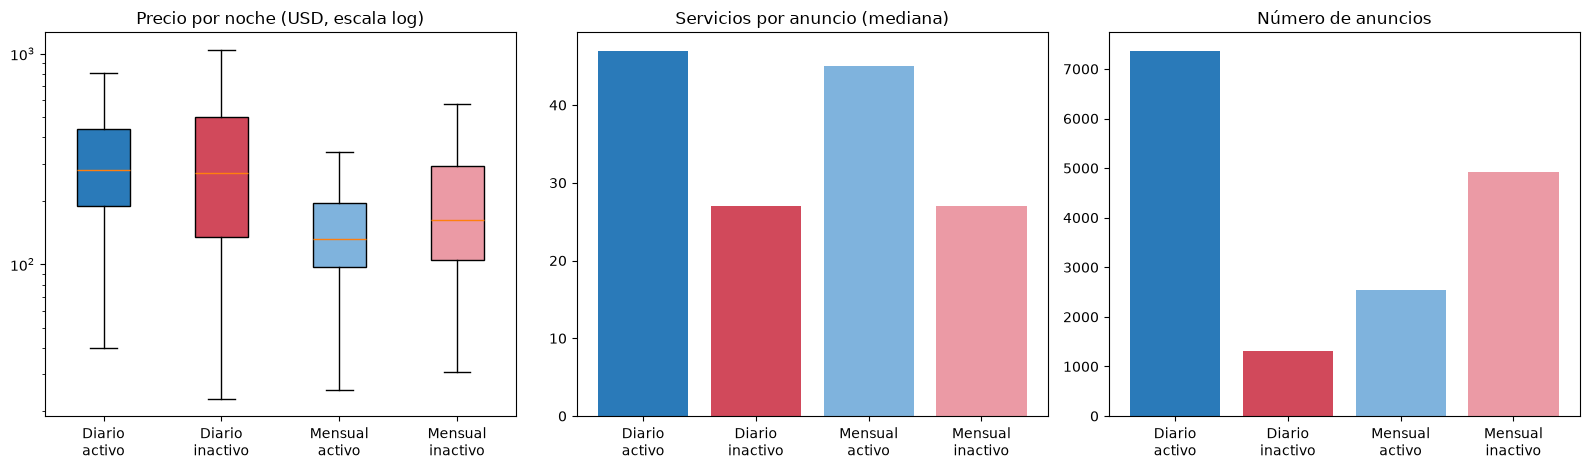

In [78]:
import matplotlib.pyplot as plt

names = list(groups)
labels = [n.replace(' · ', '\n') for n in names]
colors = ['#2a7ab9', '#d1495b', '#7fb3dd', '#eb9aa5']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

box = axes[0].boxplot([groups[n]['price_num'] for n in names], showfliers=False, patch_artist=True)
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
axes[0].set_xticks(range(1, len(names) + 1), labels)
axes[0].set_yscale('log')
axes[0].set_title('Precio por noche (USD, escala log)')

axes[1].bar(labels, [groups[n]['amenities_count'].median() for n in names], color=colors)
axes[1].set_title('Servicios por anuncio (mediana)')

axes[2].bar(labels, [len(groups[n]) for n in names], color=colors)
axes[2].set_title('Número de anuncios')

plt.tight_layout()
plt.show()

### 3.8 · Quitar columnas repetidas o constantes
En `df_diario` y `df_mensual` se eliminan:
- **Repetidas:** `is_inactive` (es lo contrario de `activo`) y `quote_is_monthly_priced` (igual a `is_monthly`).
- **Constantes por el filtro:** las marcas que se usaron para crear `df_limpio` y para dividirlo valen lo mismo en todas las filas (`is_small_host`, `has_price`, `is_hotel`, `price_outlier`, `is_monthly`, `in_target_market`).
- **Vacía en `df_mensual`:** `base_nightly_rate`, que solo existe con precio diario.

Al final se verifica que no quede ninguna columna constante.

In [79]:
REDUNDANT = ['is_inactive', 'quote_is_monthly_priced']
FILTER_FLAGS = ['is_small_host', 'has_price', 'is_hotel', 'price_outlier', 'is_monthly', 'in_target_market']

for name in ['df_diario', 'df_mensual']:
    data = globals()[name]
    drop = REDUNDANT + FILTER_FLAGS
    if name == 'df_mensual':
        drop = drop + ['base_nightly_rate']
    constant = [c for c in FILTER_FLAGS if data[c].nunique(dropna=False) == 1]
    assert constant == FILTER_FLAGS, f'{name}: estas marcas no son constantes: {set(FILTER_FLAGS) - set(constant)}'
    data = data.drop(columns=drop)

    still_constant = [c for c in data.columns if data[c].nunique(dropna=False) <= 1]
    assert not still_constant, f'{name}: quedan columnas constantes: {still_constant}'
    globals()[name] = data
    print(f'{name}: {data.shape}  (se quitaron {len(drop)} columnas)')

df_diario: (8690, 63)  (se quitaron 8 columnas)
df_mensual: (7468, 62)  (se quitaron 9 columnas)


### _Parte Daniel Babativa_


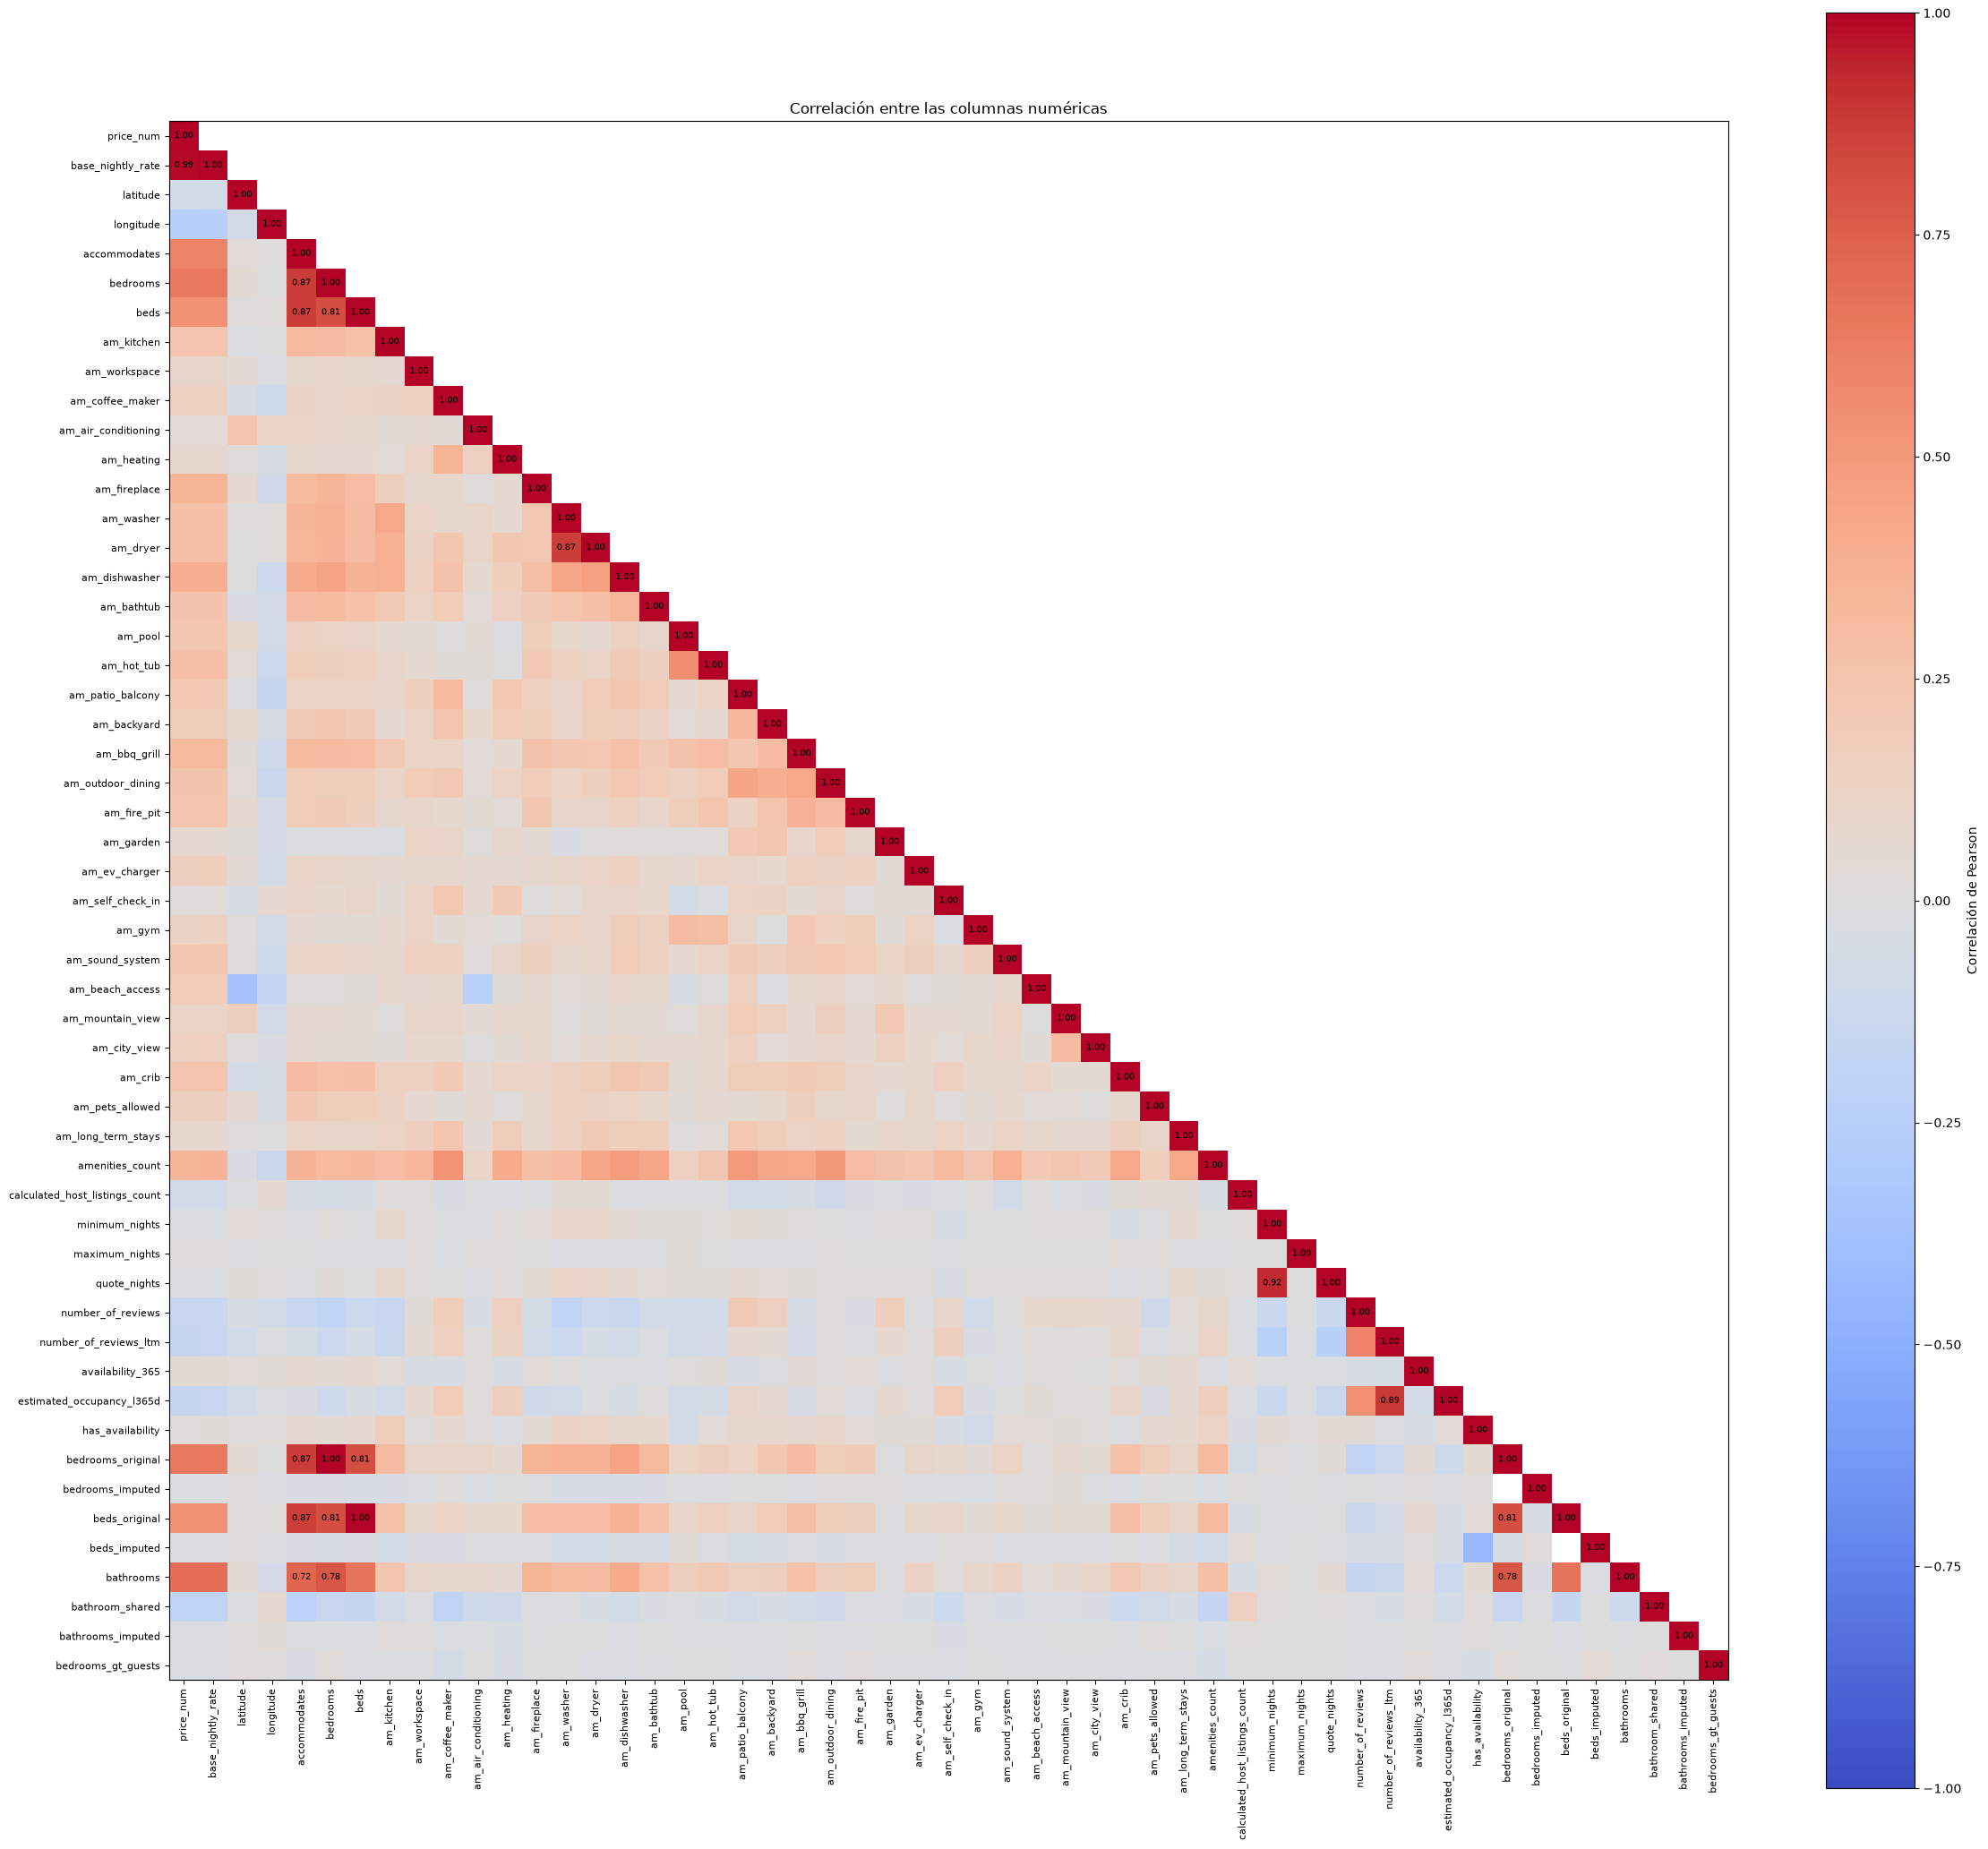

In [80]:
import numpy as np
import matplotlib.pyplot as plt

# Analizar anuncios diarios activos
train = df_diario.loc[df_diario["activo"] == 1].copy()

# Seleccionar columnas numéricas y quitar las constantes
datos_numericos = train.select_dtypes(include=["number", "bool"]).copy()
datos_numericos = datos_numericos.loc[
    :, datos_numericos.nunique(dropna=True) > 1
]

matriz_corr = datos_numericos.corr()
matriz = matriz_corr.to_numpy()

# Mostrar solo la mitad inferior de la matriz
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
matriz_grafica = np.ma.masked_where(
    mascara | ~np.isfinite(matriz),
    matriz
)

colores = plt.get_cmap("coolwarm").copy()
colores.set_bad(color="white")

cantidad_columnas = len(matriz_corr.columns)
fig, ax = plt.subplots(
    figsize=(max(14, cantidad_columnas * 0.45),
             max(12, cantidad_columnas * 0.40))
)

imagen = ax.imshow(matriz_grafica, cmap=colores, vmin=-1, vmax=1)

nombres = matriz_corr.columns
ax.set_xticks(range(cantidad_columnas))
ax.set_xticklabels(nombres, rotation=90, fontsize=8)
ax.set_yticks(range(cantidad_columnas))
ax.set_yticklabels(nombres, fontsize=8)

# Etiquetar correlaciones fuertes
for fila in range(cantidad_columnas):
    for columna in range(fila + 1):
        valor = matriz[fila, columna]
        if np.isfinite(valor) and abs(valor) >= 0.70:
            ax.text(
                columna, fila, f"{valor:.2f}",
                ha="center", va="center", fontsize=7
            )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre las columnas numéricas")
plt.tight_layout()
plt.show()

price_num y base_nightly_rate: 0,99. 
minimum_nights y quote_nights: 0,92. 
number_of_reviews_ltm y estimated_occupancy_l365d: 0,89
accommodates con bedrooms y beds: 0,87; bedrooms con beds: 0,81.
am_washer y am_dryer: 0,87.

In [81]:
# Anuncios diarios activos
train = df_diario.loc[df_diario["activo"] == 1].copy()

# Columnas que no se usarán como predictores
columnas_excluir = [
    "id",
    "base_nightly_rate",       
    "quote_nights",            
    "beds",                    
    "bedrooms_original",       
    "beds_original",           
    "number_of_reviews",       
    "number_of_reviews_ltm",   
    "last_review",             
    "availability_365",        
    "estimated_occupancy_l365d", 
    "has_availability",        
    "activo"                   
]

# El objetivo que queremos predecir
y = train["price_num"].copy()

# Matriz de predictores
X = train.drop(
    columns=["price_num"] + columnas_excluir,
    errors="ignore"
).copy()

# Base con predictores y objetivo
df_modelo = X.copy()
df_modelo["price_num"] = y

print("Columnas excluidas:")
print([col for col in columnas_excluir if col in train.columns])

print("\nTamaño de X:", X.shape)
print("Tamaño de y:", y.shape)
print("Tamaño de la base para el modelo:", df_modelo.shape)

display(df_modelo.head())

Columnas excluidas:
['id', 'base_nightly_rate', 'quote_nights', 'beds', 'bedrooms_original', 'beds_original', 'number_of_reviews', 'number_of_reviews_ltm', 'last_review', 'availability_365', 'estimated_occupancy_l365d', 'has_availability', 'activo']

Tamaño de X: (7370, 49)
Tamaño de y: (7370,)
Tamaño de la base para el modelo: (7370, 50)


,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bedrooms,bathrooms_text,am_kitchen,am_workspace,am_coffee_maker,am_air_conditioning,am_heating,am_fireplace,am_washer,am_dryer,am_dishwasher,am_bathtub,am_pool,am_hot_tub,am_patio_balcony,am_backyard,am_bbq_grill,am_outdoor_dining,am_fire_pit,am_garden,am_ev_charger,am_self_check_in,am_gym,am_sound_system,am_beach_access,am_mountain_view,am_city_view,am_crib,am_pets_allowed,am_long_term_stays,amenities_count,calculated_host_listings_count,minimum_nights,maximum_nights,bedrooms_imputed,beds_imputed,bathrooms,bathroom_shared,bathrooms_imputed,property_type_model,neighbourhood_model,bedrooms_gt_guests,price_num
10,Unincorporated Santa Monica Mountains,Unincorporated Areas,34.070540,-118.897990,Entire guesthouse,Entire home/apt,6,1.0,1 bath,1,0,1,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,40,1,2.0,28.0,0,0,1.0,0,0,Entire guesthouse,Unincorporated Santa Monica Mountains,0,162.00
41,Venice,City of Los Angeles,34.003930,-118.455920,Entire cottage,Entire home/apt,2,1.0,1 bath,1,1,1,1,1,0,1,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,46,1,2.0,1125.0,0,0,1.0,0,0,Entire cottage,Venice,0,292.50
42,Studio City,City of Los Angeles,34.139730,-118.408720,Entire guesthouse,Entire home/apt,3,1.0,1 bath,0,1,1,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,1,44,1,2.0,30.0,0,0,1.0,0,0,Entire guesthouse,Studio City,0,379.50
43,Beverly Crest,City of Los Angeles,34.093660,-118.435450,Entire home,Entire home/apt,4,2.0,2.5 baths,1,0,1,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,0,1,0,0,0,1,1,0,0,1,52,1,3.0,90.0,0,0,2.5,0,0,Entire home,Beverly Crest,0,1202.58
49,Valley Village,City of Los Angeles,34.166145,-118.412376,Entire vacation home,Entire home/apt,6,2.0,1 bath,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,1,1,0,43,2,2.0,28.0,0,0,1.0,0,0,Unique entire place,Valley Village,0,878.00


columnas excluídas de x: id, base_nightly_rate, quote_nights, beds, bedrooms_original, beds_original, number_of_reviews, number_of_reviews_ltm, last_review, availability_365, estimated_occupancy_l365d, has_availability y activo.
id: identifica el anuncio; no describe sus características.
base_nightly_rate: es otra medida del precio y correlaciona casi perfectamente con price_num. Incluirla sería darle al modelo una pista directa de la respuesta.
quote_nights: es una variable de la cotización y está muy correlacionada con minimum_nights; conservamos esta última.
beds: está muy correlacionada con accommodates y bedrooms. Se dejó fuera inicialmente para reducir redundancia; luego se puede probar si mejora el modelo al incluirla.
bedrooms_original y beds_original: se conservaron para auditar la imputación.
Variables de actividad (number_of_reviews, number_of_reviews_ltm, last_review, availability_365, estimated_occupancy_l365d, has_availability): para análisis, no para como predictores del modelo.
activo: en la muestra de entrenamiento todos los anuncios tienen valor 1, así que no ayuda a distinguirlos.


Precio original
Observaciones en la prueba: 5,000 de 7,370
Asimetría: 2.490
Estadístico Shapiro-Wilk W: 0.7716
Valor p: 4.005e-64
Se rechaza la hipótesis de normalidad al 5 %.


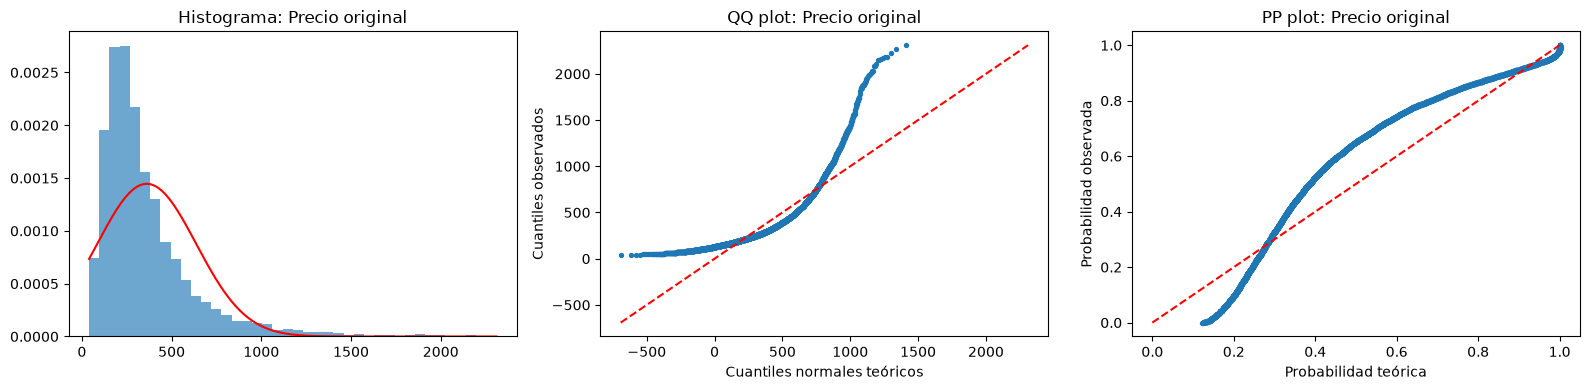


Logaritmo del precio
Observaciones en la prueba: 5,000 de 7,370
Asimetría: 0.183
Estadístico Shapiro-Wilk W: 0.9966
Valor p: 3.515e-09
Se rechaza la hipótesis de normalidad al 5 %.


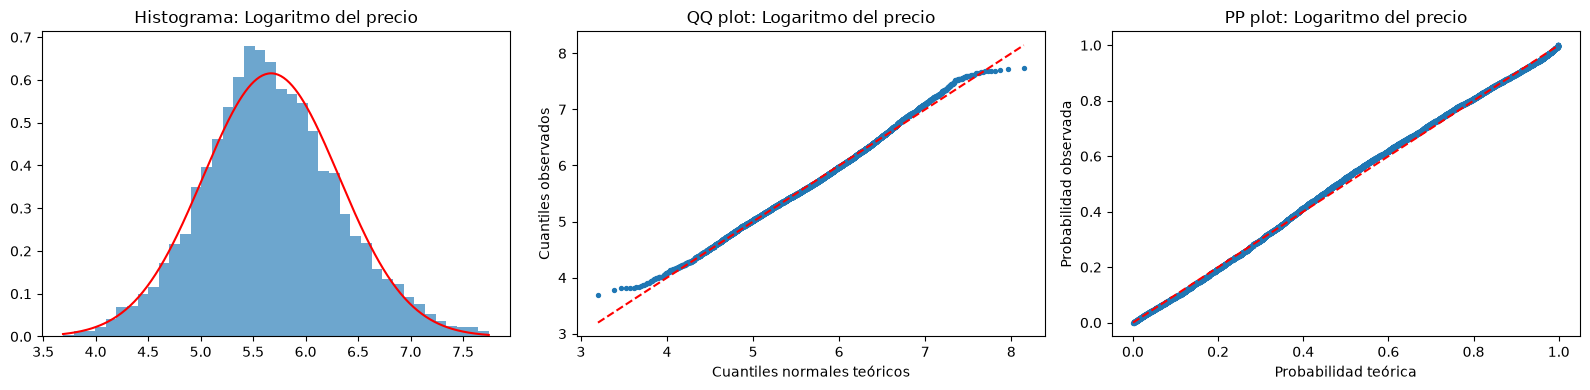

In [82]:

from scipy import stats

# Usar anuncios activos y conservar precios positivos
train = df_diario.loc[df_diario["activo"].eq(1)].copy()

precio = pd.to_numeric(train["price_num"], errors="coerce").to_numpy()
precio = precio[np.isfinite(precio) & (precio > 0)]

# Si el precio fuera lognormal, su logaritmo sería aproximadamente normal
precio_log = np.log(precio)


def evaluar_normalidad(datos, nombre):
    rng = np.random.default_rng(42)

    # Shapiro-Wilk: usar máximo 5.000 datos para que el valor p sea confiable
    n_prueba = min(len(datos), 5000)
    muestra_prueba = rng.choice(datos, size=n_prueba, replace=False)
    estadistico, p_valor = stats.shapiro(muestra_prueba)

    print(f"\n{nombre}")
    print(f"Observaciones en la prueba: {n_prueba:,} de {len(datos):,}")
    print(f"Asimetría: {stats.skew(datos):.3f}")
    print(f"Estadístico Shapiro-Wilk W: {estadistico:.4f}")
    print(f"Valor p: {p_valor:.4g}")

    if p_valor < 0.05:
        print("Se rechaza la hipótesis de normalidad al 5 %.")
    else:
        print("No se rechaza la hipótesis de normalidad al 5 %.")
        print("Esto no demuestra que los datos sean perfectamente normales.")

    # Para los gráficos, usar máximo 10.000 observaciones
    n_grafico = min(len(datos), 10000)
    muestra = np.sort(rng.choice(datos, size=n_grafico, replace=False))

    media = np.mean(datos)
    desviacion = np.std(datos, ddof=0)

    probabilidades = (np.arange(1, n_grafico + 1) - 0.5) / n_grafico
    cuantiles_normales = stats.norm.ppf(
        probabilidades, loc=media, scale=desviacion
    )

    fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

    # Histograma y curva normal estimada
    ejes[0].hist(muestra, bins=40, density=True, alpha=0.65)
    x = np.linspace(np.min(muestra), np.max(muestra), 300)
    ejes[0].plot(x, stats.norm.pdf(x, media, desviacion), color="red")
    ejes[0].set_title(f"Histograma: {nombre}")

    # QQ plot
    ejes[1].scatter(cuantiles_normales, muestra, s=8)
    limites = [
        min(cuantiles_normales.min(), muestra.min()),
        max(cuantiles_normales.max(), muestra.max())
    ]
    ejes[1].plot(limites, limites, "r--")
    ejes[1].set_title(f"QQ plot: {nombre}")
    ejes[1].set_xlabel("Cuantiles normales teóricos")
    ejes[1].set_ylabel("Cuantiles observados")

    # PP plot
    probabilidades_teoricas = stats.norm.cdf(
        muestra, loc=media, scale=desviacion
    )
    ejes[2].scatter(probabilidades_teoricas, probabilidades, s=8)
    ejes[2].plot([0, 1], [0, 1], "r--")
    ejes[2].set_title(f"PP plot: {nombre}")
    ejes[2].set_xlabel("Probabilidad teórica")
    ejes[2].set_ylabel("Probabilidad observada")

    plt.tight_layout()
    plt.show()


evaluar_normalidad(precio, "Precio original")
evaluar_normalidad(precio_log, "Logaritmo del precio")

Precio original: asimetría 2,490; QQ y PP plots se alejan bastante de la línea.
Log del precio: asimetría 0,183; \(D=0,0242\); los gráficos se acercan mucho más a la línea.    
Shapiro–Wilk rechaza la normalida

In [83]:
train_log = df_diario.loc[df_diario["activo"].eq(1)].copy()

train_log["price_num"] = pd.to_numeric(
    train_log["price_num"], errors="coerce"
)

train_log = train_log.loc[
    train_log["price_num"].gt(0)
    & np.isfinite(train_log["price_num"])
].copy()

train_log["price_log"] = np.log(train_log["price_num"])

train_log[["price_num", "price_log"]].head()

,price_num,price_log
10,162.00,5.087596
41,292.50,5.678465
42,379.50,5.938855
43,1202.58,7.092225
49,878.00,6.777647


In [84]:
corr_price_log = (
    train_log.select_dtypes(include=np.number)
    .corr()["price_log"]
    .drop(["price_log", "price_num"], errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(corr_price_log.to_frame("correlacion_con_price_log"))

,correlacion_con_price_log
base_nightly_rate,0.888091
bedrooms_original,0.662521
bedrooms,0.662310
accommodates,0.656638
bathrooms,0.631088
beds,0.576693
beds_original,0.576303
am_dishwasher,0.463063
amenities_count,0.414676
am_bbq_grill,0.331335


In [85]:
# Añadir el logaritmo al dataframe de precios diarios
df_diario["price_log"] = np.log(
    df_diario["price_num"].where(df_diario["price_num"] > 0)
)

assert df_diario["price_log"].notna().all()

In [86]:
train = df_diario.loc[df_diario["activo"].eq(1)].copy()

y = train["price_log"].copy()

X = train.drop(
    columns=["price_num", "price_log"] + columnas_excluir,
    errors="ignore"
).copy()

df_modelo = X.copy()
df_modelo["price_log"] = y